# A 3D pouch cell DFN with tabs

This notebook builds a DFN for a single-layer pouch cell on a full 3D mesh: both current collectors with their tabs, both electrodes and the separator, coupled to a 3D heat equation. Unlike the [pouch cell model](./pouch-cell-model.ipynb), it makes no thin-cell reduction, and unlike `BasicDFNUnstructured` it resolves the current collectors and tabs.

The model is written from scratch on a `pybamm.BaseModel` and discretised with the unstructured finite volume method, `pybamm.FiniteVolumeUnstructured`.

In [1]:
%pip install "pybamm[plot,cite,vtk]" -q    # install PyBaMM if it is not installed
import itertools
import tempfile

import numpy as np
from IPython.display import Image

import pybamm
from pybamm.meshes.unstructured_submesh import _hex_grid

## Mesh

Each of the five layers gets its own hexahedral mesh. The layers share their $y$ and $z$ grid lines, so the meshes join up at the interfaces, and the $y$ grid includes the tab edges. A current collector is meshed over the bounding box of its body and tab, and the cells beside the tab are dropped. We tag only the faces that boundary conditions refer to: the two through-cell faces of each layer (`"left"` and `"right"`), which `pybamm.compute_interface_data` pairs up across neighbouring layers, and the top of each tab (`"tab_top"`). Every untagged boundary face has zero flux.

In [2]:
parameter_values = pybamm.ParameterValues("Marquis2019")
param = pybamm.LithiumIonParameters()


def value(symbol):
    return float(parameter_values.evaluate(symbol))


def tab_span(electrode):
    centre, width = value(electrode.centre_y_tab), value(electrode.L_tab)
    return centre - width / 2, centre + width / 2


L_y, L_z, tab_height = value(param.L_y), value(param.L_z), 0.01
tab_n, tab_p = tab_span(param.n), tab_span(param.p)

y_knots = np.unique([0, *tab_n, *tab_p, L_y])
y_edges = np.unique([np.linspace(a, b, 3) for a, b in itertools.pairwise(y_knots)])
z_edges = np.append(np.linspace(0, L_z, 11), np.linspace(L_z, L_z + tab_height, 4)[1:])


def layer_mesh(x_edges, tab=None):
    nodes, elements = _hex_grid(x_edges, y_edges, z_edges)
    _, y, z = nodes[elements].mean(axis=1).T
    keep = z < L_z
    if tab is not None:
        keep |= (y > tab[0]) & (y < tab[1])
    used, elements = np.unique(elements[keep], return_inverse=True)
    mesh = pybamm.UnstructuredSubMesh(nodes[used], elements.reshape(-1, 8))

    x, _, z = mesh.face_centroids.T
    tags = {
        "left": np.isclose(x, x_edges[0], rtol=0, atol=1e-10) & (z < L_z),
        "right": np.isclose(x, x_edges[-1], rtol=0, atol=1e-10) & (z < L_z),
        "tab_top": np.isclose(z, L_z + tab_height),
    }
    mesh.boundary_faces = {
        tag: np.flatnonzero(on) for tag, on in tags.items() if on.any()
    }
    return mesh


layers = {  # thickness, cells through the thickness, tab
    "negative current collector": (param.n.L_cc, 2, tab_n),
    "negative electrode": (param.n.L, 4, None),
    "separator": (param.s.L, 3, None),
    "positive electrode": (param.p.L, 4, None),
    "positive current collector": (param.p.L_cc, 2, tab_p),
}
meshes, x = {}, 0
for domain, (thickness, n_x, tab) in layers.items():
    meshes[domain] = layer_mesh(np.linspace(x, x + value(thickness), n_x + 1), tab)
    x += value(thickness)
for left, right in itertools.pairwise(layers):
    pybamm.compute_interface_data(meshes[left], meshes[right], left, right)
print({domain: mesh.npts for domain, mesh in meshes.items()})

{'negative current collector': 212, 'negative electrode': 400, 'separator': 300, 'positive electrode': 400, 'positive current collector': 212}


## Model

The solid potential spans each current collector and its electrode, the electrolyte spans the electrodes and separator, and the temperature spans all five layers. Each is a concatenation of one variable per layer.

In [3]:
model = pybamm.BaseModel(name="3D pouch cell DFN")
ncc, n, s, p, pcc = layers


def per_layer(name, domains):
    return [pybamm.Variable(f"{name} in {domain}", domain) for domain in domains]


phi_s_ncc, phi_s_n = per_layer("Solid potential [V]", [ncc, n])
phi_s_p, phi_s_pcc = per_layer("Solid potential [V]", [p, pcc])
c_e_n, c_e_s, c_e_p = per_layer("Electrolyte concentration [mol.m-3]", [n, s, p])
phi_e_n, phi_e_s, phi_e_p = per_layer("Electrolyte potential [V]", [n, s, p])
T_ncc, T_n, T_s, T_p, T_pcc = per_layer("Temperature [K]", layers)
c_s_n, c_s_p = (
    pybamm.Variable(
        f"{electrode.capitalize()} particle concentration [mol.m-3]",
        f"{electrode} particle",
        auxiliary_domains={"secondary": f"{electrode} electrode"},
    )
    for electrode in ["negative", "positive"]
)

phi_s_negative = pybamm.concatenation(phi_s_ncc, phi_s_n)
phi_s_positive = pybamm.concatenation(phi_s_p, phi_s_pcc)
c_e = pybamm.concatenation(c_e_n, c_e_s, c_e_p)
phi_e = pybamm.concatenation(phi_e_n, phi_e_s, phi_e_p)
T = pybamm.concatenation(T_ncc, T_n, T_s, T_p, T_pcc)
T_e = pybamm.concatenation(T_n, T_s, T_p)


no_flux = {"left": (0, "Neumann"), "right": (0, "Neumann")}


def by_layer(values):
    return pybamm.concatenation(
        *(pybamm.PrimaryBroadcast(value, domain) for domain, value in values.items())
    )

The cell is discharged at 1C for 30 minutes and then rests. The reactions follow Butler–Volmer kinetics and generate reversible and irreversible heat; ohmic heating is left out for brevity.

In [4]:
discharging = pybamm.t < 1800


def reaction(electrode, c_s, c_e, phi_s, phi_e, T):
    c_s_surf = pybamm.surf(c_s)
    sto_surf = c_s_surf / electrode.prim.c_max
    eta = phi_s - phi_e - electrode.prim.U(sto_surf, T)
    j0 = electrode.prim.j0(c_e, c_s_surf, T)
    j = 2 * j0 * pybamm.sinh(electrode.prim.ne * param.F * eta / (2 * param.R * T))
    a = 3 * electrode.prim.epsilon_s_av / electrode.prim.R_typ
    return j, a * j, a * j * (eta + T * electrode.prim.dUdT(sto_surf))


j_n, a_j_n, heat_n = reaction(param.n, c_s_n, c_e_n, phi_s_n, phi_e_n, T_n)
j_p, a_j_p, heat_p = reaction(param.p, c_s_p, c_e_p, phi_s_p, phi_e_p, T_p)
a_j = pybamm.concatenation(a_j_n, pybamm.PrimaryBroadcast(0, s), a_j_p)

Lithium diffuses in a spherical particle at every point of each electrode.

In [5]:
for c_s, j, T_electrode, electrode in [
    (c_s_n, j_n, T_n, param.n),
    (c_s_p, j_p, T_p, param.p),
]:
    D = electrode.prim.D(c_s, pybamm.PrimaryBroadcast(T_electrode, c_s.domain))
    model.rhs[c_s] = pybamm.div(D * pybamm.grad(c_s))
    model.boundary_conditions[c_s] = {
        "left": (0, "Neumann"),
        "right": (-j / (param.F * pybamm.surf(D)), "Neumann"),
    }
    model.initial_conditions[c_s] = electrode.prim.c_init

Charge is conserved in the solid of each current collector and its electrode. The negative tab is grounded, and the cell current leaves through the top of the positive tab. The equations are multiplied by a length scale so that their residuals are of order one.

In [6]:
length_scale = param.L_x**2 * param.L_z**2
tab_area = value(param.p.L_cc) * (tab_p[1] - tab_p[0])
tab_current_density = (
    param.current_density_with_time * discharging * L_y * L_z / tab_area
)
active_n = pybamm.Parameter("Negative electrode active material volume fraction")
active_p = pybamm.Parameter("Positive electrode active material volume fraction")

sigma_negative = pybamm.concatenation(
    pybamm.PrimaryBroadcast(param.n.sigma_cc, ncc),
    param.n.sigma(None, T_n) * active_n**param.n.b_s,
)
source_negative = pybamm.concatenation(pybamm.PrimaryBroadcast(0, ncc), a_j_n)
model.algebraic[phi_s_negative] = length_scale * (
    pybamm.div(-sigma_negative * pybamm.grad(phi_s_negative)) + source_negative
)
model.boundary_conditions[phi_s_negative] = {**no_flux, "tab_top": (0, "Dirichlet")}
model.initial_conditions[phi_s_negative] = 0

sigma_positive = pybamm.concatenation(
    param.p.sigma(None, T_p) * active_p**param.p.b_s,
    pybamm.PrimaryBroadcast(param.p.sigma_cc, pcc),
)
source_positive = pybamm.concatenation(a_j_p, pybamm.PrimaryBroadcast(0, pcc))
model.algebraic[phi_s_positive] = length_scale * (
    pybamm.div(-sigma_positive * pybamm.grad(phi_s_positive)) + source_positive
)
model.boundary_conditions[phi_s_positive] = {
    **no_flux,
    "tab_top": (-tab_current_density / param.p.sigma_cc, "Neumann"),
}
model.initial_conditions[phi_s_positive] = param.ocv_init

The electrolyte equations are the DFN's, with gradients in all three directions.

In [7]:
porosity = by_layer(
    {d: pybamm.Parameter(f"{d.capitalize()} porosity") for d in [n, s, p]}
)
tortuosity = porosity ** by_layer({n: param.n.b_e, s: param.s.b_e, p: param.p.b_e})
kappa = param.kappa_e(c_e, T_e) * tortuosity

model.algebraic[phi_e] = length_scale * (
    pybamm.div(kappa * param.chiRT_over_Fc(c_e, T_e) * pybamm.grad(c_e))
    - pybamm.div(kappa * pybamm.grad(phi_e))
    - a_j
)
model.boundary_conditions[phi_e] = no_flux
model.initial_conditions[phi_e] = -param.n.prim.U_init

model.rhs[c_e] = (
    pybamm.div(tortuosity * param.D_e(c_e, T_e) * pybamm.grad(c_e))
    + (1 - param.t_plus(c_e, T_e)) * a_j / param.F
) / porosity
model.boundary_conditions[c_e] = no_flux
model.initial_conditions[c_e] = param.c_e_init

Heat is conducted through all five layers, each with its own properties. The cell is insulated except at the tabs, whose tops are held at the ambient temperature.

In [8]:
T_init = param.T_init
rho_c_p = by_layer(
    {
        ncc: param.n.therm.rho_c_p_cc(T_init),
        n: param.n.therm.rho_c_p(T_init),
        s: param.s.therm.rho_c_p(T_init),
        p: param.p.therm.rho_c_p(T_init),
        pcc: param.p.therm.rho_c_p_cc(T_init),
    }
)
conductivity = by_layer(
    {
        ncc: param.n.therm.lambda_cc(T_init),
        n: param.n.therm.lambda_(T_init),
        s: param.s.therm.lambda_(T_init),
        p: param.p.therm.lambda_(T_init),
        pcc: param.p.therm.lambda_cc(T_init),
    }
)
heat = pybamm.concatenation(
    pybamm.PrimaryBroadcast(0, ncc),
    heat_n,
    pybamm.PrimaryBroadcast(0, s),
    heat_p,
    pybamm.PrimaryBroadcast(0, pcc),
)
model.rhs[T] = (pybamm.div(conductivity * pybamm.grad(T)) + heat) / rho_c_p
T_amb = param.T_amb(0, 0, pybamm.t)
model.boundary_conditions[T] = {**no_flux, "tab_top": (T_amb, "Dirichlet")}
model.initial_conditions[T] = T_init

The voltage is the mean potential over the top of the positive tab, since the negative tab is at 0 V.

In [9]:
voltage = pybamm.BoundaryIntegral(phi_s_pcc, region="tab_top") / tab_area
model.variables = {"Voltage [V]": voltage, "Cell temperature [K]": T}
model.events = [
    pybamm.Event("Minimum voltage [V]", voltage - param.voltage_low_cut),
    pybamm.Event("Maximum voltage [V]", param.voltage_high_cut - voltage),
]

## Solve

The five layers use the meshes built above, and the particles use the usual 1D finite volume method. Including 1800 s in `t_eval` makes the solver stop at the step in current rather than step across it.

In [10]:
class PrebuiltMesh(pybamm.MeshGenerator):
    def __init__(self, mesh):
        super().__init__(pybamm.UnstructuredSubMesh)
        self.mesh = mesh

    def __call__(self, lims, npts):
        return self.mesh


geometry = {
    "negative particle": {"r_n": {"min": 0, "max": param.n.prim.R_typ}},
    "positive particle": {"r_p": {"min": 0, "max": param.p.prim.R_typ}},
    "current collector": {"z": {"position": 0}},
}
submesh_types = {
    "negative particle": pybamm.Uniform1DSubMesh,
    "positive particle": pybamm.Uniform1DSubMesh,
    "current collector": pybamm.SubMesh0D,
}
spatial_methods = {
    "negative particle": pybamm.FiniteVolume(),
    "positive particle": pybamm.FiniteVolume(),
    "current collector": pybamm.ZeroDimensionalSpatialMethod(),
}
var_pts = {"r_n": 10, "r_p": 10}
for i, (domain, mesh) in enumerate(meshes.items()):
    # pybamm.Mesh needs a coordinate per domain, which the prebuilt meshes ignore
    x = pybamm.SpatialVariable(f"x_{i}", domain)
    geometry[domain] = {
        x: {"min": mesh.vertices[:, 0].min(), "max": mesh.vertices[:, 0].max()}
    }
    submesh_types[domain] = PrebuiltMesh(mesh)
    spatial_methods[domain] = pybamm.FiniteVolumeUnstructured()
    var_pts[x] = mesh.npts

simulation = pybamm.Simulation(
    model,
    geometry=geometry,
    parameter_values=parameter_values,
    submesh_types=submesh_types,
    var_pts=var_pts,
    spatial_methods=spatial_methods,
)
solution = simulation.solve(
    np.array([0, 1800, 3600]), t_interp=np.linspace(0, 3600, 61)
)

## Results

`pybamm.VTKQuickPlot` draws unstructured-mesh variables in 3D. Here we stretch the through-cell direction 100 times so that the cell reads as a slab, and save an animation of the discharge and rest: the cell heats up, coolest near the tabs that carry heat away, and cools back down once the current stops. With a display, `solution.plot(backend="vtk")` opens the same view with a time slider instead.

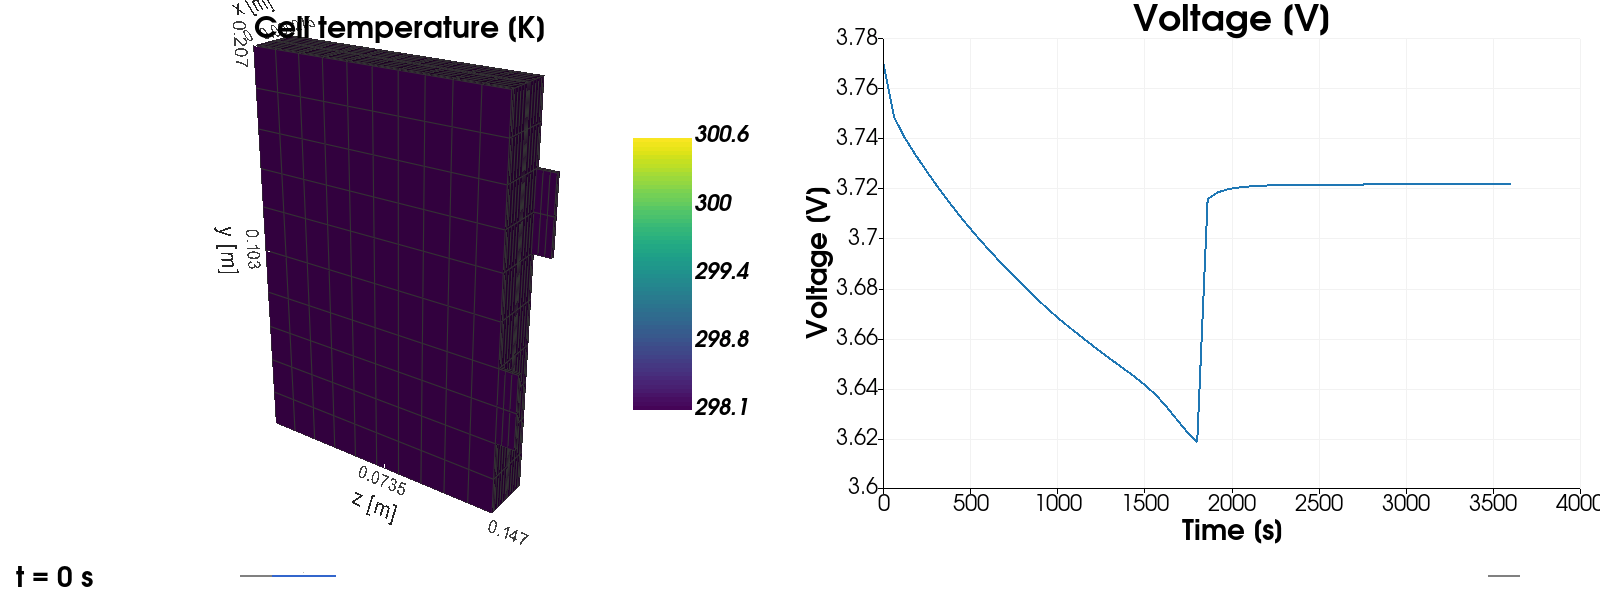

In [11]:
plot = pybamm.VTKQuickPlot(
    solution,
    ["Cell temperature [K]", "Voltage [V]"],
    options={"Cell temperature [K]": {"scale": (100, 1, 1)}},
)
with tempfile.TemporaryDirectory() as folder:
    plot.save_gif(f"{folder}/pouch.gif", fps=3, n_frames=10, width=1600, height=600)
    animation = Image(filename=f"{folder}/pouch.gif")
animation

In [12]:
pybamm.print_citations()

[1] Joel A. E. Andersson, Joris Gillis, Greg Horn, James B. Rawlings, and Moritz Diehl. CasADi – A software framework for nonlinear optimization and optimal control. Mathematical Programming Computation, 11(1):1–36, 2019. doi:10.1007/s12532-018-0139-4.
[2] Charles R. Harris, K. Jarrod Millman, Stéfan J. van der Walt, Ralf Gommers, Pauli Virtanen, David Cournapeau, Eric Wieser, Julian Taylor, Sebastian Berg, Nathaniel J. Smith, and others. Array programming with NumPy. Nature, 585(7825):357–362, 2020. doi:10.1038/s41586-020-2649-2.
[3] Alan C. Hindmarsh. The PVODE and IDA algorithms. Technical Report, Lawrence Livermore National Lab., CA (US), 2000. doi:10.2172/802599.
[4] Alan C. Hindmarsh, Peter N. Brown, Keith E. Grant, Steven L. Lee, Radu Serban, Dan E. Shumaker, and Carol S. Woodward. SUNDIALS: Suite of nonlinear and differential/algebraic equation solvers. ACM Transactions on Mathematical Software (TOMS), 31(3):363–396, 2005. doi:10.1145/1089014.1089020.
[5] Scott G. Marquis, Vale